In [12]:
from google.colab import files
uploaded = files.upload()


Saving manufacturing_dataset_1000_samples.csv to manufacturing_dataset_1000_samples (1).csv


In [13]:
import pandas as pd
df = pd.read_csv('manufacturing_dataset_1000_samples.csv')

In [14]:

print("Dataset successfully loaded!")
print(f"Shape of the dataset: {df.shape}\n")
display(df.head())
print("\nMissing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset successfully loaded!
Shape of the dataset: (1000, 19)



,Timestamp,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,2023-01-01 00:00:00,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,2023-01-01 01:00:00,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,2023-01-01 02:00:00,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,2023-01-01 03:00:00,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0
4,2023-01-01 04:00:00,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0



Missing values in each column:
Material_Viscosity     20
Ambient_Temperature    20
Operator_Experience    20
dtype: int64


In [15]:
# 1. Process the Timestamp Column
# Convert the string Timestamp to actual datetime objects
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Extract the 'Hour' as a new feature (helps predict hourly output)
df['Hour'] = df['Timestamp'].dt.hour

# Drop the original Timestamp column
df = df.drop('Timestamp', axis=1)
print("Timestamp column processed and dropped.")

# 2. Handle Missing Values
# Define the columns with missing data
missing_cols = ['Material_Viscosity', 'Ambient_Temperature', 'Operator_Experience']

# Impute missing values with the median of each respective column
for col in missing_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

print("\nMissing values remaining after imputation:")
print(df.isnull().sum().sum()) # This should now output 0

# Display the updated dataframe shape and first few rows
print(f"\nUpdated Dataset Shape: {df.shape}")
display(df.head())

Timestamp column processed and dropped.

Missing values remaining after imputation:
0

Updated Dataset Shape: (1000, 19)


,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour,Hour
0,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5,0
1,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9,1
2,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9,2
3,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0,3
4,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0,4


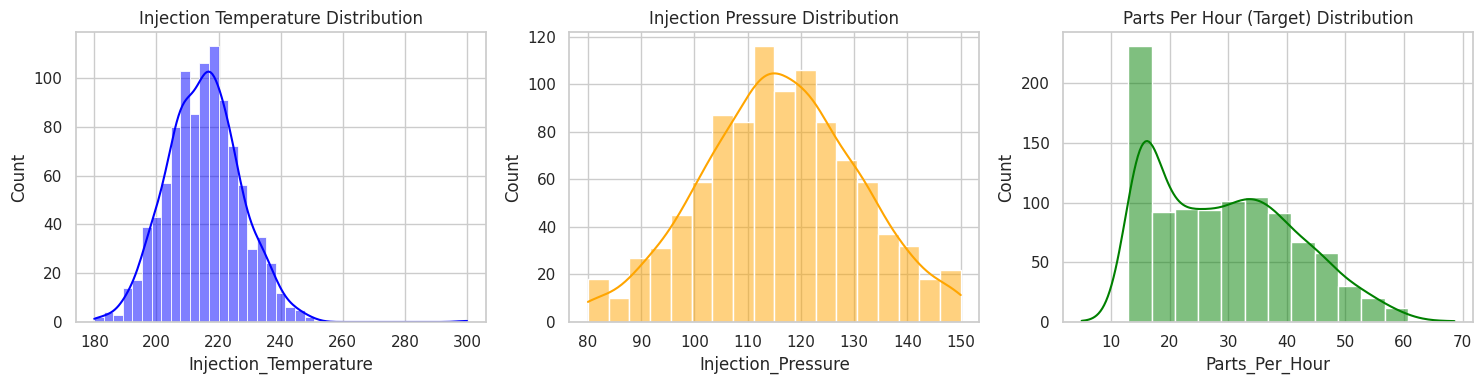

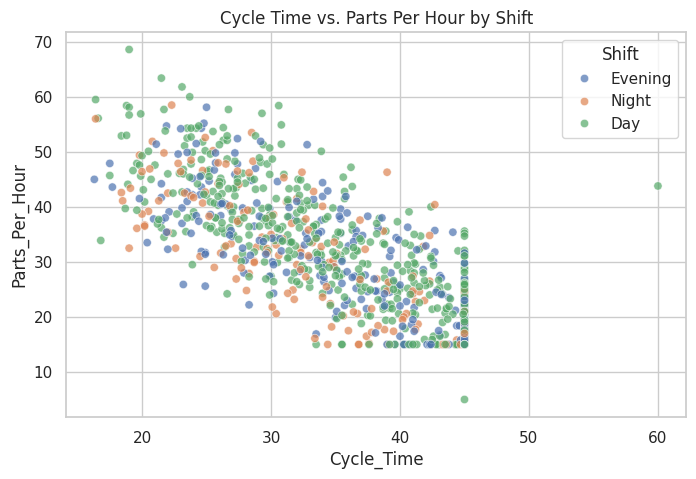

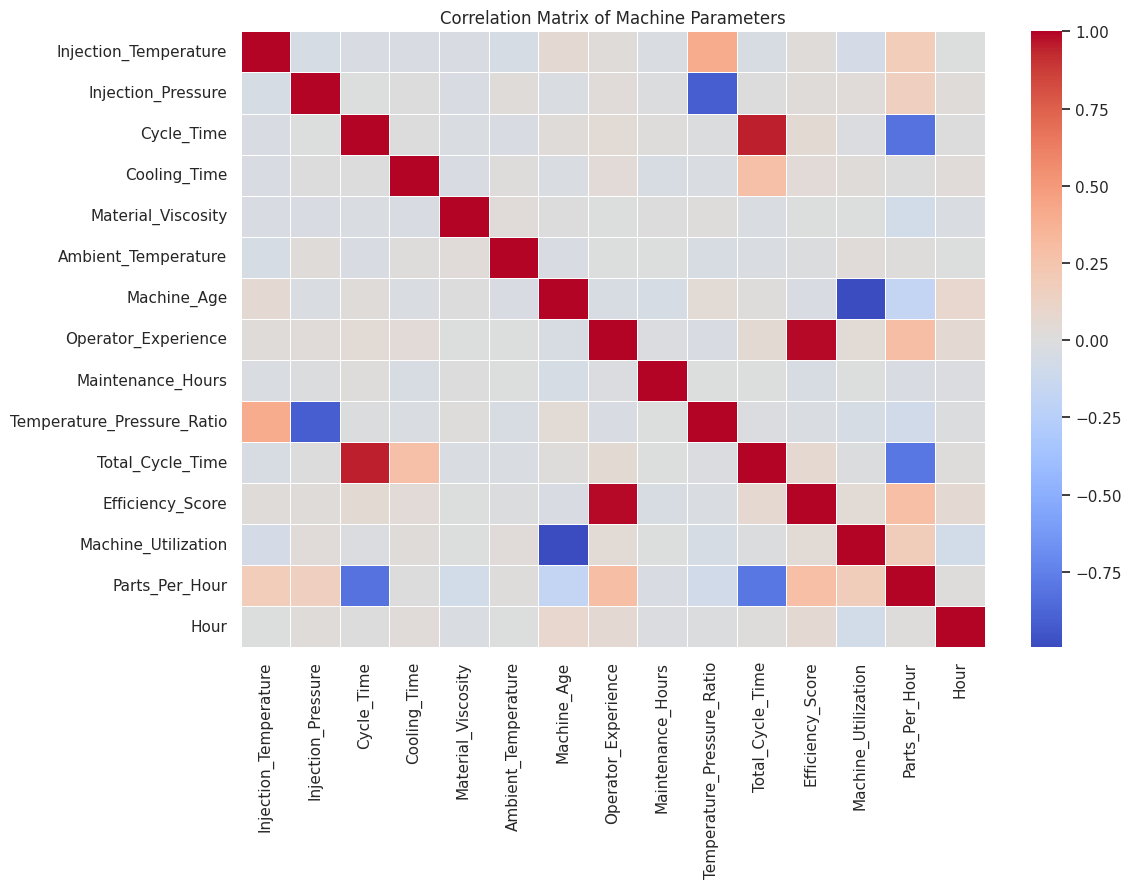

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Histograms: Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['Injection_Temperature'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Injection Temperature Distribution')
sns.histplot(df['Injection_Pressure'], kde=True, ax=axes[1], color='orange')
axes[1].set_title('Injection Pressure Distribution')
sns.histplot(df['Parts_Per_Hour'], kde=True, ax=axes[2], color='green')
axes[2].set_title('Parts Per Hour (Target) Distribution')
plt.tight_layout()
plt.show()

# 2. Scatter Plot: Effect of settings on production
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Cycle_Time', y='Parts_Per_Hour', hue='Shift', data=df, alpha=0.7)
plt.title('Cycle Time vs. Parts Per Hour by Shift')
plt.show()

# 3. Correlation Matrix (Numerical features only)
plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int32', 'int64']).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Machine Parameters')
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Encode Categorical Variables
categorical_cols = ['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']
# pd.get_dummies applies One-Hot Encoding. drop_first=True prevents multicollinearity.
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(f"Shape after One-Hot Encoding: {df_encoded.shape}")

# 2. Define Target Variable and Features
X = df_encoded.drop('Parts_Per_Hour', axis=1) # Features
y = df_encoded['Parts_Per_Hour']              # Target

# 3. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# 4. Feature Scaling
scaler = StandardScaler()
# We fit the scaler ONLY on the training data to prevent data leakage, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

print("\nData successfully encoded, split, and scaled! First 3 rows of processed training data:")
display(X_train_scaled_df.head(3))

Shape after One-Hot Encoding: (1000, 27)
Training set shape: (800, 26)
Testing set shape: (200, 26)

Data successfully encoded, split, and scaled! First 3 rows of processed training data:


,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Temperature_Pressure_Ratio,...,Machine_Type_Type_B,Machine_Type_Type_C,Material_Grade_Premium,Material_Grade_Standard,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday
0,-0.324673,-1.133765,-1.490551,0.418948,-0.802496,1.489849,-1.237700,-0.637789,-0.339420,0.870459,...,-0.733799,-0.586973,-0.531085,0.835771,-0.397168,-0.413888,-0.36489,-0.426244,2.491427,-0.418023
1,0.024724,-1.721740,-1.882535,1.166088,-0.639089,0.399416,0.834246,-0.320785,-0.396682,1.763303,...,-0.733799,1.703655,1.882938,-1.196499,-0.397168,-0.413888,-0.36489,-0.426244,-0.401376,-0.418023
2,-0.341717,1.901824,1.110801,0.462897,-1.259762,-0.254843,1.831849,-0.447587,-0.053110,-1.520176,...,1.362770,-0.586973,-0.531085,0.835771,-0.397168,-0.413888,-0.36489,-0.426244,-0.401376,-0.418023


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# 1. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("Model training complete!")

# 2. Make predictions on the unseen testing data
y_pred = model.predict(X_test_scaled)

# 3. Calculate Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # RMSE is just the square root of MSE
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Evaluation Metrics ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared Score: {r2:.4f}")

# 4. Create a comparison dataframe to see Actual vs Predicted side-by-side
results_df = pd.DataFrame({
    'Actual_Parts_Per_Hour': y_test,
    'Predicted_Parts_Per_Hour': np.round(y_pred, 1),
    'Difference': np.round(y_test - y_pred, 1)
})

print("\n--- Actual vs Predicted (First 5 Rows) ---")
display(results_df.head())

Model training complete!

--- Model Evaluation Metrics ---
Mean Squared Error (MSE): 12.3150
Root Mean Squared Error (RMSE): 3.5093
Mean Absolute Error (MAE): 2.7154
R-squared Score: 0.9056

--- Actual vs Predicted (First 5 Rows) ---


,Actual_Parts_Per_Hour,Predicted_Parts_Per_Hour,Difference
521,18.6,19.9,-1.3
737,42.8,44.4,-1.6
740,34.2,34.1,0.1
660,40.0,39.7,0.3
411,15.0,18.3,-3.3
